# 03 · Clasificación de severidad de la enfermedad (EA2)

**Pregunta:** ¿se puede anticipar `severity_of_illness` (Minor / Moderate / Extreme) a partir de edad, condiciones preexistentes, tipo de ingreso, días de estadía y visitantes? Caso de uso: triaje predictivo.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))  # permite `import src...` sin rutas absolutas

import pandas as pd
pd.set_option("display.max_columns", 30)
from src import config
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
from src.models.train_classification import run_classification, FEATURES, TARGET
from src.utils.reporter import ModelSummaryReporter, load_json, save_json

## 1. Datos y distribución de clases

In [2]:
df = pd.read_csv(config.PROCESSED_CSV)
print(df.shape, "| predictoras:", FEATURES, "| objetivo:", TARGET)
display(df[TARGET].value_counts(normalize=True).rename("proporción").to_frame())

(100000, 14) | predictoras: ['age_midpoint', 'stay_in_days', 'visitors_with_patient', 'health_conditions', 'type_of_admission'] | objetivo: severity_of_illness


,proporción
severity_of_illness,
Moderate,0.56067
Minor,0.26186
Extreme,0.17747


Las clases están **desbalanceadas** (Moderate domina), por lo que la exactitud sola engaña: se reportan además precisión, recall y F1 ponderados y el desglose por clase.

## 2. Algoritmo y configuración
**Random Forest** dentro de un `Pipeline` (imputación + `OneHotEncoder` para las categóricas): captura relaciones no lineales e interacciones sin escalado. Parámetros: `n_estimators=100`, `max_depth=12`, `min_samples_leaf=50`, `class_weight="balanced"`, `random_state=42`. División **estratificada** 80/20 con `random_state=42`. Los pasos de preprocesamiento se ajustan solo con entrenamiento.

In [3]:
run = run_classification(df)
res = run.results
print(res["algorithm"]); print(res["parameters"]); print(res["split"])

RandomForestClassifier dentro de un Pipeline (imputación + OneHotEncoder)
{'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 50, 'class_weight': 'balanced', 'n_jobs': -1, 'random_state': 42}
{'test_size': 0.2, 'random_state': 42, 'stratified': True, 'n_train': 80000, 'n_test': 20000}


## 3. Métricas y matriz de confusión

,valor
accuracy,0.469750
precision_weighted,0.526839
recall_weighted,0.469750
f1_weighted,0.479778
accuracy_baseline_mayoritaria,0.560650


,precision,recall,f1-score,support
Minor,0.360511,0.398511,0.378560,5237.0
Moderate,0.664717,0.455989,0.540915,11213.0
Extreme,0.336708,0.618310,0.435992,3550.0


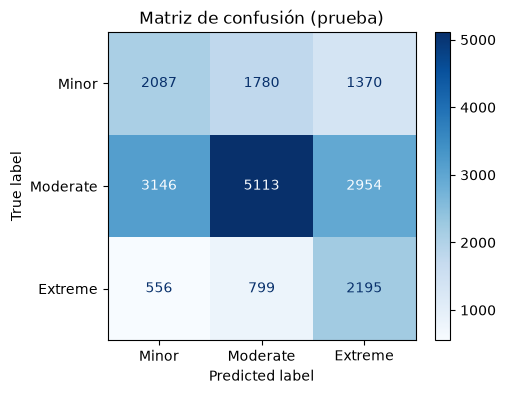

In [4]:
display(pd.Series(res["metrics"], name="valor").to_frame())
display(pd.DataFrame(res["per_class"]).T)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(run.y_test, run.y_pred, labels=res["classes"], cmap="Blues", ax=ax)
ax.set_title("Matriz de confusión (prueba)"); plt.show()

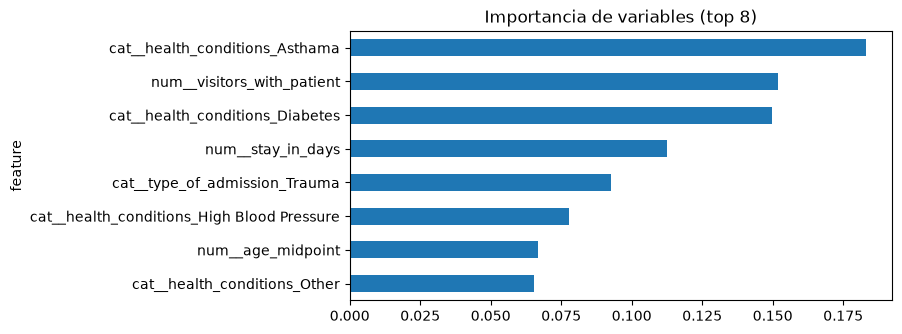

In [5]:
imp = pd.DataFrame(res["top_feature_importances"]).set_index("feature")["importance"]
imp.sort_values().plot.barh(figsize=(7, 3.5), title="Importancia de variables (top 8)"); plt.show()

## 4. Interpretación y limitaciones (generadas desde los resultados)

In [6]:
print("\n".join("- " + t for t in res["interpretation"]))
print("\nLimitaciones:")
print("\n".join("- " + t for t in res["limitations"]))

- Exactitud=0.4698 frente a 0.5606 de predecir siempre la clase mayoritaria. La exactitud queda por debajo de esa referencia: class_weight='balanced' sacrifica exactitud global para mejorar el recall de las clases minoritarias.
- Clase mejor reconocida (mayor recall): Extreme (recall=0.618).
- Clase peor reconocida (menor recall): Minor (recall=0.399).
- Error más frecuente: pacientes Moderate clasificados como Minor (3146 casos).

Limitaciones:
- Las variables predictoras disponibles tienen poder discriminante limitado; las métricas muestran cuánto, y no deben usarse como herramienta clínica real.
- El modelo aprende de una muestra reproducible del dataset, no de todos sus registros.
- class_weight='balanced' mejora el recall de las clases minoritarias a costa de precisión.
- Edad y días de estadía pueden ser consecuencia de la gravedad, no solo causa predictiva.
- Datos de salud: cualquier uso real exigiría validación clínica, auditoría de sesgos y privacidad.


**Cómo leerlo:** compara la exactitud con la referencia de la clase mayoritaria. Con `class_weight="balanced"` el modelo prioriza reconocer las clases minoritarias (mayor recall en `Extreme`) a costa de exactitud global. Los errores se concentran entre niveles adyacentes de severidad. Las variables disponibles tienen poder discriminante limitado, así que no es apto para uso clínico real.

## 5. Guardar resultados y generar `reports/model-summary.txt`
Se combinan los resultados de este notebook con los de regresión (`02-…`) y la metadata de ingestión (`01-…`).

In [7]:
save_json(res, config.CLASSIFICATION_RESULTS_JSON)
ruta = ModelSummaryReporter().save(
    load_json(config.INGESTION_METADATA_JSON),
    load_json(config.REGRESSION_RESULTS_JSON),
    res,
)
print("Generado:", ruta.relative_to(ROOT))
print("\n".join(ruta.read_text(encoding="utf-8").splitlines()[:40]))

Generado: reports/model-summary.txt
RESUMEN AUTOMÁTICO DE MODELOS - EA2
Fecha y hora de ejecución: 2026-10-25 16:44:06 UTC+0000

1. DATASET
----------------------------------------------------------------------
Identificador: Nicolybgs/healthcare_data
URL: https://huggingface.co/datasets/Nicolybgs/healthcare_data
Configuración / split: default / train
Filas en Hugging Face: 500000
Muestreo: muestra aleatoria de 100000 filas (seed=42)
Dimensiones iniciales (filas x columnas): 100000 x 15
Columnas iniciales: Available Extra Rooms in Hospital, Department, Ward_Facility_Code, doctor_name, staff_available, patientid, Age, gender, Type of Admission, Severity of Illness, health_conditions, Visitors with Patient, Insurance, Admission_Deposit, Stay (in days)
Dimensiones tras el preprocesamiento: 100000 x 14
Columnas procesadas: available_extra_rooms_in_hospital, department, ward_facility_code, doctor_name, staff_available, gender, type_of_admission, severity_of_illness, health_conditions, visit